# **1. 데이터 가져오기, 하나로 병합**

코드 설명

---




*   [Veronesi] CH 5.4.1 참고
*   http://www.smbs.biz/Exchange/IRS.jsp 에서 IRS 금리 데이터 가져오기


*   http://www.smbs.biz/Bond/BondMajor.jsp 에서 CD 금리 가져오기 >>> 2.810%

*   데이터 하나로 병합: CD 금리를 0.25Y 앵커로 지정, IRS 데이터에서 Mid price만 남기기









In [4]:
import pandas as pd

# Load the IRS rate data from the provided CSV file
try:
    df = pd.read_csv('/content/IRS rate_data_20260226.csv', encoding='utf-8')

    maturity_column = df.columns[0]

    new_row_data = {maturity_column: '0.25Y (CD 금리)'}
    rate_columns = [col for col in df.columns if df[col].dtype in ['float64', 'int64']]

    if rate_columns:
        new_row_data[rate_columns[0]] = float('2.810')
    else:
        new_row_data['Rate'] = float('2.810')

    new_row_df = pd.DataFrame([new_row_data], columns=df.columns)

    # Append the new row to the existing DataFrame temporarily
    df_with_cd = pd.concat([df, new_row_df], ignore_index=True)

    # Extract the CD rate row (the last one)
    cd_rate_row = df_with_cd.iloc[[-1]].copy() # Use .copy() to avoid SettingWithCopyWarning

    # Filter CD rate row to keep '기일물' and 'Receive', then rename 'Receive' to 'Mid'
    cd_rate_row = cd_rate_row[[maturity_column, 'Receive']].rename(columns={'Receive': 'Mid'})

    # Filter the original IRS data (all rows except the last one) to keep '기일물' and 'Mid'
    irs_data_filtered = df_with_cd.iloc[:-1][[maturity_column, 'Mid']]

    # Concatenate the CD rate row at the top, followed by the filtered IRS data
    df = pd.concat([cd_rate_row, irs_data_filtered], ignore_index=True)

    print("Updated IRS data with CD rate (reordered and filtered):")
    print(df)

except FileNotFoundError:
    print("Error: 'IRS rate_data_20260226.csv' not found. Please ensure the file is uploaded.")
except Exception as e:
    print(f"An error occurred: {e}")

Updated IRS data with CD rate (reordered and filtered):
              기일물     Mid
0   0.25Y (CD 금리)  2.8100
1              1Y  2.8850
2              2Y  3.0400
3              3Y  3.1350
4              4Y  3.1975
5              5Y  3.2525
6              7Y  3.3250
7             10Y  3.3825
8             12Y  3.4050
9             15Y  3.4150
10            20Y  3.3300


# **2. 데이터 선형보간**

코드 설명

---
$$
c(T)=c_a+\left(c_b-c_a\right) \times \frac{T-T_a}{T_b-T_a}
$$

공식 이용하여 선형보간


In [5]:
import pandas as pd
import numpy as np
import re
from scipy.interpolate import interp1d

# The 'df' DataFrame from the previous step is available in the kernel:
# It already contains the CD rate at 0.25Y and filtered IRS 'Mid' rates.

# 1. Parse '기일물' column to numerical years
# This function converts maturity strings like '1Y' to 1.0, and handles the '0.25Y (CD 금리)' case.
def parse_maturity_to_float(maturity_str):
    if 'CD 금리' in maturity_str:
        return 0.25
    match = re.match(r'(\d+(\.\d+)?)Y', maturity_str)
    if match:
        return float(match.group(1))
    return np.nan # Should not occur with the expected data

df['Years'] = df['기일물'].apply(parse_maturity_to_float)

# Ensure 'Mid' column is numeric (already done in previous step, but good for robustness)
df['Mid'] = pd.to_numeric(df['Mid'])

# Filter the data to only include points relevant for interpolation up to 10.0 years.
# This excludes points like 12Y, 15Y, 20Y that are beyond the target interpolation range.
df_interpolation_base = df[(df['Years'] >= 0.25) & (df['Years'] <= 10.0)].copy()

# Sort by Years to ensure correct order for interpolation
df_interpolation_base = df_interpolation_base.sort_values(by='Years').reset_index(drop=True)

# Extract known time points (x-coordinates) and their corresponding rates (y-coordinates)
known_years = df_interpolation_base['Years'].values
known_rates = df_interpolation_base['Mid'].values

# 2. Define target maturities: 0.25, 0.5, 0.75, ..., 10.0 years (total 40 nodes)
target_years = np.arange(0.25, 10.25, 0.25)

# 3. Perform linear interpolation using scipy's interp1d function.
# 'kind="linear"' corresponds to the provided linear interpolation formula.
# 'fill_value="extrapolate"' is used to handle potential floating point edge cases at boundaries,
# although all target_years should strictly be within the known_years range for interpolation.
f_interp = interp1d(known_years, known_rates, kind='linear', fill_value="extrapolate")

# Apply the interpolator to the target years to get the interpolated rates
interpolated_rates = f_interp(target_years)

# Create a new DataFrame for the interpolated swap curve
swap_curve_df = pd.DataFrame({
    'Years': target_years,
    'Swap Rate (Mid)': interpolated_rates
})

print("Interpolated Swap Curve (0.25Y to 10.0Y quarterly):")
print(swap_curve_df)


Interpolated Swap Curve (0.25Y to 10.0Y quarterly):
    Years  Swap Rate (Mid)
0    0.25         2.810000
1    0.50         2.835000
2    0.75         2.860000
3    1.00         2.885000
4    1.25         2.923750
5    1.50         2.962500
6    1.75         3.001250
7    2.00         3.040000
8    2.25         3.063750
9    2.50         3.087500
10   2.75         3.111250
11   3.00         3.135000
12   3.25         3.150625
13   3.50         3.166250
14   3.75         3.181875
15   4.00         3.197500
16   4.25         3.211250
17   4.50         3.225000
18   4.75         3.238750
19   5.00         3.252500
20   5.25         3.261563
21   5.50         3.270625
22   5.75         3.279688
23   6.00         3.288750
24   6.25         3.297813
25   6.50         3.306875
26   6.75         3.315937
27   7.00         3.325000
28   7.25         3.329792
29   7.50         3.334583
30   7.75         3.339375
31   8.00         3.344167
32   8.25         3.348958
33   8.50         3.353750
34 

# **3. SWAP Curve 구축**

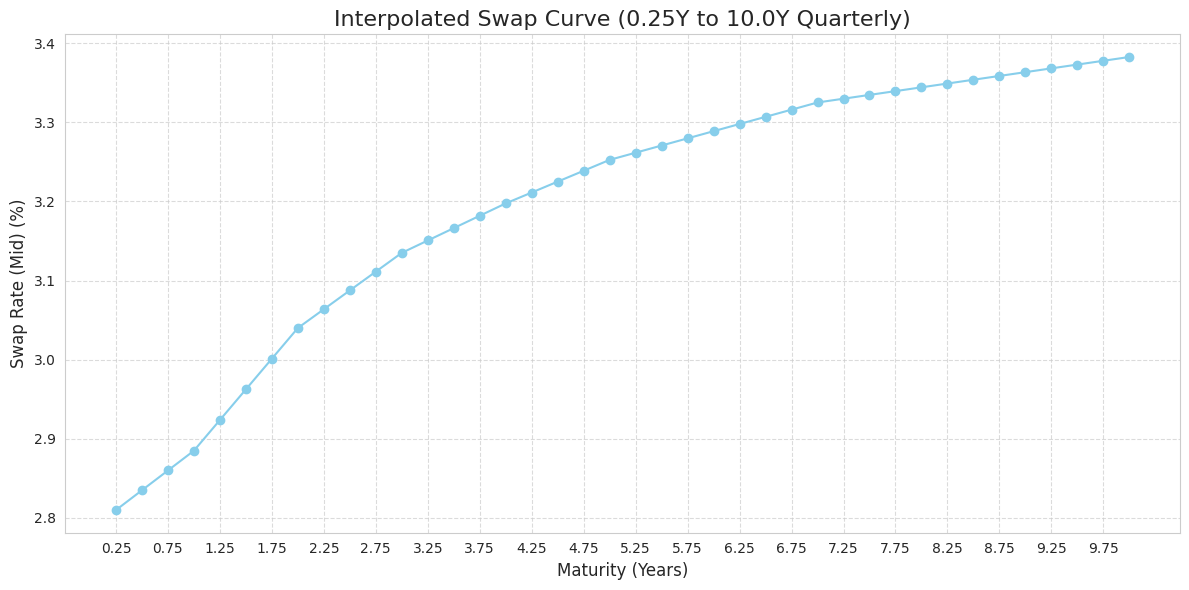

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the plot is displayed inline in the notebook
%matplotlib inline

# Set a style for better aesthetics (optional)
sns.set_style("whitegrid")

# Create the plot
plt.figure(figsize=(12, 6))
plt.plot(swap_curve_df['Years'], swap_curve_df['Swap Rate (Mid)'], marker='o', linestyle='-', color='skyblue')

# Add title and labels
plt.title('Interpolated Swap Curve (0.25Y to 10.0Y Quarterly)', fontsize=16)
plt.xlabel('Maturity (Years)', fontsize=12)
plt.ylabel('Swap Rate (Mid) (%)', fontsize=12)

# Add grid for better readability
plt.grid(True, linestyle='--', alpha=0.7)

# Add tooltips or specific annotations if desired (for interactive plots, need different libraries)
# For static plots, just show the plot

# Set x-axis ticks to match the quarterly intervals
plt.xticks(np.arange(0.25, 10.25, 0.5))

# Improve layout and display the plot
plt.tight_layout()
plt.show()


# **4. DF 부트스트래핑**

코드 설명

---
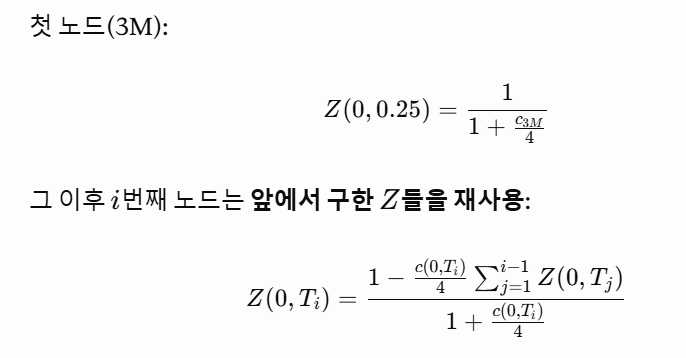



In [8]:
import numpy as np
import pandas as pd

# Ensure swap_curve_df is available from the previous steps
# If this cell is run independently, make sure swap_curve_df is defined.

# Initialize a list to store the discount factors
discount_factors = []

# Extract the swap rates (c(0, Ti)) from the swap_curve_df
# Rates are assumed to be in percentage, convert to decimal for calculation
swap_rates_decimal = swap_curve_df['Swap Rate (Mid)'].values / 100
quarterly_term = 0.25 # Corresponds to n=4, so T_j increments by 0.25

# First node (i=0, corresponds to 0.25Y or 3M)
# Z(0, 0.25) = 1 / (1 + c_3M / 4)
c_3M = swap_rates_decimal[0] # The rate at 0.25Y
Z_0_25 = 1 / (1 + c_3M / 4)
discount_factors.append(Z_0_25)

# Subsequent nodes (i=1 to 39)
# Z(0,Ti) = (1 - c(0,Ti)/4 * sum(Z(0,Tj) for j=1 to i-1)) / (1 + c(0,Ti)/4)
for i in range(1, len(swap_curve_df)):
    current_swap_rate = swap_rates_decimal[i] # c(0, Ti)

    # Sum of previous Z(0, Tj) - adjusted for the formula notation
    # The formula uses sum(Z(0,Tj)) * c(0,Ti)/4, which implies that c(0,Ti)/4 is applied to each term,
    # but a more common interpretation of a par swap rate bootstrap uses it differently.
    # Given the formula provided, we'll interpret sum(Z(0,Tj)) for j=1 to i-1 as the sum of discount factors
    # for the preceding periods, multiplied by current_swap_rate/4.

    # Let's clarify the sum: sum(Z(0,Tj)) for j=1 to i-1. In our case, j is the index of the previous time steps.
    # The sum should be over the actual discount factors calculated so far.

    # The formula provided seems to be for quarterly payments.
    # Sum of discount factors for previous payment periods, assuming quarterly payments.
    # The 'sum' in the formula corresponds to sum of Z for actual payment dates before T_i.
    # Since our target_years are already quarterly, the sum will just be over previously calculated Zs.

    sum_of_previous_Z = np.sum(discount_factors) # This sum implicitly includes Z(0, 0.25) up to Z(0, T_{i-1})

    numerator = 1 - (current_swap_rate / 4) * sum_of_previous_Z
    denominator = 1 + (current_swap_rate / 4)

    Z_i = numerator / denominator
    discount_factors.append(Z_i)

# Add the calculated discount factors to the swap_curve_df
swap_curve_df['Discount Factor (Z)'] = discount_factors

print("Swap Curve with calculated Discount Factors:")
print(swap_curve_df)


Swap Curve with calculated Discount Factors:
    Years  Swap Rate (Mid)  Discount Factor (Z)
0    0.25         2.810000             0.993024
1    0.50         2.835000             0.985974
2    0.75         2.860000             0.978851
3    1.00         2.885000             0.971658
4    1.25         2.923750             0.964230
5    1.50         2.962500             0.956670
6    1.75         3.001250             0.948983
7    2.00         3.040000             0.941172
8    2.25         3.063750             0.933562
9    2.50         3.087500             0.925900
10   2.75         3.111250             0.918188
11   3.00         3.135000             0.910428
12   3.25         3.150625             0.902870
13   3.50         3.166250             0.895302
14   3.75         3.181875             0.887723
15   4.00         3.197500             0.880136
16   4.25         3.211250             0.872615
17   4.50         3.225000             0.865095
18   4.75         3.238750             0.85

# **5. 10년 IRS valuation**

In [9]:
import numpy as np
import pandas as pd

# Fixed swap rate (c) as a decimal
c = 0.037

# Principal amount (not explicitly stated but implied by formulas with 100)
principal = 100

# Get discount factors from the previously calculated swap_curve_df
# Ensure swap_curve_df is available in the environment
if 'swap_curve_df' not in locals():
    print("Error: 'swap_curve_df' is not defined. Please ensure previous cells are run.")
else:
    # Sum of all discount factors Z(0, Tj) for j=1 to 40 (from 0.25Y to 10.0Y)
    sum_Z_0_Tj = swap_curve_df['Discount Factor (Z)'].sum()

    # Z(0, 10) is the discount factor for 10 years
    # Find the row where Years is 10.0 and get its Discount Factor (Z)
    Z_0_10 = swap_curve_df[swap_curve_df['Years'] == 10.0]['Discount Factor (Z)'].iloc[0]

    # Calculate P_fixed using the provided formula:
    # P_fixed = (c / 4) * 100 * sum(Z(0, Tj)) + Z(0, 10) * 100
    P_fixed = (c / 4) * principal * sum_Z_0_Tj + Z_0_10 * principal

    # Calculate V_swap using the provided formula:
    # V_swap = 100 - P_fixed
    V_swap = principal - P_fixed

    print(f"Assumed Fixed Swap Rate (c): {c*100:.3f}%")
    print(f"Sum of Discount Factors (sum(Z(0, Tj)) for j=1 to 40): {sum_Z_0_Tj:.6f}")
    print(f"Discount Factor Z(0, 10): {Z_0_10:.6f}")
    print(f"Calculated Fixed Leg Value (P_fixed): {P_fixed:.4f}")
    print(f"Calculated Swap Value (V_swap): {V_swap:.4f}")

    # Interpretation based on V_swap sign
    market_par_rate_10Y = swap_curve_df[swap_curve_df['Years'] == 10.0]['Swap Rate (Mid)'].iloc[0] / 100

    print(f"\nMarket 10-year par rate (c*): {market_par_rate_10Y*100:.3f}%")
    print(f"Fixed Rate (c): {c*100:.3f}%")

    if V_swap > 0:
        print(f"Interpretation: V_swap > 0. This implies c* ({market_par_rate_10Y*100:.3f}%) > c (3.700%). The fixed payer is in a favorable position (pays less than market).")
    elif V_swap < 0:
        print(f"Interpretation: V_swap < 0. This implies c* ({market_par_rate_10Y*100:.3f}%) < c (3.700%). The fixed payer is in an unfavorable position (pays more than market).")
    else:
        print(f"Interpretation: V_swap = 0. This implies c* ({market_par_rate_10Y*100:.3f}%) = c (3.700%). The swap is at par.")


Assumed Fixed Swap Rate (c): 3.700%
Sum of Discount Factors (sum(Z(0, Tj)) for j=1 to 40): 33.965542
Discount Factor Z(0, 10): 0.712779
Calculated Fixed Leg Value (P_fixed): 102.6960
Calculated Swap Value (V_swap): -2.6960

Market 10-year par rate (c*): 3.383%
Fixed Rate (c): 3.700%
Interpretation: V_swap < 0. This implies c* (3.383%) < c (3.700%). The fixed payer is in an unfavorable position (pays more than market).


### 결과 요약

*   **계산된 스왑 가치 (V_swap)**: -2.6960
*   **해석**: 고정 금리 지급자가 시장의 10년 파 스왑 금리(3.383%)보다 높은 3.700%의 고정 금리를 지급하고 있으므로, 이 스왑은 고정 금리 지급자에게 **불리한(Out of the Money) 상태**입니다.

# **6.  1bp 충격 후 재부트스트랩 → 듀레이션**

In [10]:
import numpy as np
import pandas as pd

# --- Helper Function for Bootstrapping Discount Factors ---
def bootstrap_discount_factors(swap_rates_decimal_array, quarterly_term=0.25):
    """
    Bootstraps discount factors from a series of quarterly swap rates.
    Assumes the first rate corresponds to 0.25Y.
    """
    discount_factors = []

    # First node (0.25Y)
    c_3M = swap_rates_decimal_array[0]
    Z_0_25 = 1 / (1 + c_3M / 4)
    discount_factors.append(Z_0_25)

    # Subsequent nodes
    for i in range(1, len(swap_rates_decimal_array)):
        current_swap_rate = swap_rates_decimal_array[i]
        sum_of_previous_Z = np.sum(discount_factors)

        numerator = 1 - (current_swap_rate / 4) * sum_of_previous_Z
        denominator = 1 + (current_swap_rate / 4)

        Z_i = numerator / denominator
        discount_factors.append(Z_i)

    return np.array(discount_factors)

# --- Helper Function for Swap Valuation ---
def calculate_swap_value(rates_df, fixed_swap_rate, principal=100):
    """
    Calculates the swap value (V_swap) given a DataFrame of swap rates,
    a fixed swap rate, and principal.

    Args:
        rates_df (pd.DataFrame): DataFrame with 'Years' and 'Swap Rate (Mid)' columns.
                                 'Swap Rate (Mid)' should be in percentage (e.g., 2.81 for 2.81%).
        fixed_swap_rate (float): The fixed rate 'c' of the swap (e.g., 0.037 for 3.7%).
        principal (int): The principal amount.

    Returns:
        float: The calculated V_swap.
    """
    # 1. Prepare swap rates for bootstrapping (convert to decimal)
    swap_rates_decimal = rates_df['Swap Rate (Mid)'].values / 100

    # 2. Bootstrap discount factors
    discount_factors_array = bootstrap_discount_factors(swap_rates_decimal)

    # 3. Find Z(0, 10) for valuation
    # Ensure 10.0Y exists in the rates_df
    if 10.0 not in rates_df['Years'].values:
        raise ValueError("10.0Y maturity not found in the provided rates_df for swap valuation.")

    index_10Y = rates_df[rates_df['Years'] == 10.0].index[0]
    Z_0_10 = discount_factors_array[index_10Y]

    # 4. Calculate P_fixed
    sum_Z_0_Tj = np.sum(discount_factors_array)
    P_fixed = (fixed_swap_rate / 4) * principal * sum_Z_0_Tj + Z_0_10 * principal

    # 5. Calculate V_swap
    V_swap = principal - P_fixed

    return V_swap

# --- Main Execution for Duration Analysis ---

# Ensure initial conditions are met: swap_curve_df, c, principal
# From previous cells:
# c = 0.037 (fixed swap rate in decimal)
# principal = 100
# swap_curve_df is the DataFrame with quarterly interpolated rates and base discount factors.

# --- 0. Calculate initial swap value V(0) ---
V_0 = calculate_swap_value(swap_curve_df, c, principal)
print(f"Initial Swap Value V(0): {V_0:.4f}")

# --- 1. Parallel Shift (DV01) ---
print("\n--- Parallel Shift (DV01) ---")
# Create a shocked DataFrame by adding 1bp (0.01% as rates are percentages) to all swap rates
swap_curve_df_parallel_shocked = swap_curve_df.copy()
swap_curve_df_parallel_shocked['Swap Rate (Mid)'] += 0.01 # Add 1bp (0.0001 in decimal)

V_plus_1bp_parallel = calculate_swap_value(swap_curve_df_parallel_shocked, c, principal)
dv01_parallel = V_plus_1bp_parallel - V_0

print(f"Swap Value V(+1bp) (Parallel Shift): {V_plus_1bp_parallel:.4f}")
print(f"Parallel Shift DV01: {dv01_parallel:.6f}")

# --- 2. Key Rate Duration (KRD) ---
print("\n--- Key Rate Duration (KRD) ---")

# Define key tenors (using original 'known_years' from the interpolation basis)
# These are the maturities where the IRS data was initially available, up to 10Y.
# From the kernel state: known_years = array([ 0.25,  1.  ,  2.  ,  3.  ,  4.  ,  5.  ,  7.  , 10.  ])
key_tenors = np.array([0.25, 1.0, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0])

krd_results = {}
sum_of_krds = 0.0

for tenor in key_tenors:
    # Create a copy of the original swap rates for this specific shock
    swap_curve_df_krd_shocked = swap_curve_df.copy()

    # Find the index of the current tenor in the swap_curve_df
    tenor_indices = swap_curve_df_krd_shocked[swap_curve_df_krd_shocked['Years'] == tenor].index

    if len(tenor_indices) == 0:
        print(f"Warning: Key tenor {tenor}Y not found exactly in swap_curve_df. Skipping.")
        continue

    # Apply 1bp shock only to the rate at the current tenor
    swap_curve_df_krd_shocked.loc[tenor_indices, 'Swap Rate (Mid)'] += 0.01

    # Recalculate swap value with the shocked curve
    V_shocked_krd = calculate_swap_value(swap_curve_df_krd_shocked, c, principal)

    # Calculate KRD for this tenor
    krd = V_shocked_krd - V_0
    krd_results[f"{tenor}Y"] = krd
    sum_of_krds += krd

    print(f"KRD for {tenor}Y: {krd:.6f}")

print("\nKRD Results:")
for tenor, krd_val in krd_results.items():
    print(f"  {tenor}: {krd_val:.6f}")

print(f"\nSum of KRDs: {sum_of_krds:.6f}")
print(f"Parallel Shift DV01: {dv01_parallel:.6f}")

# Verify sum of KRDs approximates Parallel DV01
print(f"\nDifference (Sum of KRDs - Parallel DV01): {sum_of_krds - dv01_parallel:.6f}")


Initial Swap Value V(0): -2.6960

--- Parallel Shift (DV01) ---
Swap Value V(+1bp) (Parallel Shift): -2.6098
Parallel Shift DV01: 0.086172

--- Key Rate Duration (KRD) ---
KRD for 0.25Y: 0.000001
KRD for 1.0Y: 0.000006
KRD for 2.0Y: 0.000012
KRD for 3.0Y: 0.000018
KRD for 4.0Y: 0.000024
KRD for 5.0Y: 0.000031
KRD for 7.0Y: 0.000044
KRD for 10.0Y: 0.084979

KRD Results:
  0.25Y: 0.000001
  1.0Y: 0.000006
  2.0Y: 0.000012
  3.0Y: 0.000018
  4.0Y: 0.000024
  5.0Y: 0.000031
  7.0Y: 0.000044
  10.0Y: 0.084979

Sum of KRDs: 0.085115
Parallel Shift DV01: 0.086172

Difference (Sum of KRDs - Parallel DV01): -0.001057


 **고정 금리를 지급하는 사람(Fixed-Rate Payer)** 입장에서 스왑 가치를 계산했습니다. 이 스왑 가치는 `V_swap = 100 - P_fixed` 라는 공식으로 구합니다. 여기서 `P_fixed`는 미래에 지급해야 할 고정 금리의 현재 가치입니다.

*   **금리가 오르면 (1bp 상승)**:
    *   미래 돈의 가치를 현재로 가져올 때 쓰는 **할인율(Discount Factor)이 낮아집니다.** (더 강하게 할인)
    *   그래서 미래에 낼 고정 금리의 **현재 가치(`P_fixed`)가 낮아집니다.** (싸게 느껴짐)
    *   `100 - P_fixed` 공식에서 `P_fixed`가 줄어들면, 전체 **스왑 가치(`V_swap`)는 증가**하게 됩니다.

**한마디로, 고정 금리를 내는 입장에서는 금리가 오를수록 미래에 내야 할 돈의 현재 가치가 싸지므로 스왑의 가치가 올라간다고 볼 수 있습니다.** 그래서 DV01이 양수(`0.086172`)로 나온 것입니다.

# **7. 이론적 8년 swap rate 역산 + 검증**

In [11]:
import numpy as np
import pandas as pd

# Assume swap_curve_df and the helper functions (bootstrap_discount_factors,
# calculate_swap_value) from previous cells are available in the environment.
# The 'calculate_swap_value' function needs to be generalized for N-year swaps.

# --- Generalized N-Year Swap Valuation Function ---
def calculate_n_year_swap_value(rates_df_for_bootstrap, fixed_swap_rate, swap_tenor_years, principal=100):
    """
    Calculates the value of an N-year swap.

    Args:
        rates_df_for_bootstrap (pd.DataFrame): DataFrame with 'Years' and 'Swap Rate (Mid)' columns.
                                              Used to bootstrap discount factors.
        fixed_swap_rate (float): The fixed rate 'c' of the N-year swap (e.g., 0.037 for 3.7%).
        swap_tenor_years (float): The maturity of the swap in years (e.g., 8.0 for an 8-year swap).
        principal (int): The principal amount.

    Returns:
        float: The calculated V_swap for the N-year swap.
    """
    # Filter the rates_df_for_bootstrap to only include relevant data up to swap_tenor_years
    # This is crucial for bootstrapping discount factors specific to the N-year swap's tenor.
    rates_df_filtered = rates_df_for_bootstrap[rates_df_for_bootstrap['Years'] <= swap_tenor_years].copy()

    if rates_df_filtered.empty or rates_df_filtered['Years'].max() < swap_tenor_years:
        raise ValueError(f"Not enough data in rates_df to bootstrap for {swap_tenor_years} years. Max available: {rates_df_for_bootstrap['Years'].max()}Y")

    # 1. Prepare swap rates for bootstrapping (convert to decimal)
    swap_rates_decimal = rates_df_filtered['Swap Rate (Mid)'].values / 100

    # 2. Bootstrap discount factors
    # This uses the bootstrap_discount_factors helper from the previous cell.
    discount_factors_array = bootstrap_discount_factors(swap_rates_decimal)

    # 3. Find Z(0, N) for valuation, where N is swap_tenor_years
    # This Z(0,N) is the discount factor for the principal payment at maturity.
    # Ensure the exact tenor exists in the filtered data.
    if swap_tenor_years not in rates_df_filtered['Years'].values:
        # If the exact tenor is not a direct node in rates_df_filtered, it means
        # the interpolated points are not exact, which shouldn't happen with np.arange(0.25, 10.25, 0.25).
        # However, for robustness, we can take the last one or re-interpolate Z_0_n if needed.
        # For now, we assume exact match due to how swap_curve_df was constructed.
        raise ValueError(f"{swap_tenor_years}Y maturity not found exactly in the filtered rates_df for Z(0,N). Consider re-interpolation if needed.")

    index_n_year = rates_df_filtered[rates_df_filtered['Years'] == swap_tenor_years].index[0]
    Z_0_n = discount_factors_array[index_n_year]

    # 4. Calculate P_fixed
    # Sum of all discount factors for the *payment periods* of the N-year swap.
    # Since the swap pays quarterly, the sum is over all Zs up to N years.
    sum_Z_0_Tj_n_year = np.sum(discount_factors_array)

    P_fixed = (fixed_swap_rate / 4) * principal * sum_Z_0_Tj_n_year + Z_0_n * principal

    # 5. Calculate V_swap
    V_swap = principal - P_fixed

    return V_swap


# --- 1. Calculate Theoretical 8-Year Swap Rate (Par Rate) ---
print("--- 8-Year Par Swap Rate Calculation ---")

# Get Z(0,8) - Discount Factor for 8 years
# 8 years = 32 quarterly periods
Z_0_8 = swap_curve_df[swap_curve_df['Years'] == 8.0]['Discount Factor (Z)'].iloc[0]

# Sum of Discount Factors for all quarterly nodes up to 8 years (32 nodes)
# This is sum(Z(0,Tj)) for j=1 to 32, which means Years <= 8.0
sum_Z_0_Tj_up_to_8Y = swap_curve_df[swap_curve_df['Years'] <= 8.0]['Discount Factor (Z)'].sum()

# Calculate the 8-Year par swap rate (c_8Y) using the provided formula:
# c_8Y = 4 * (1 - Z(0,8)) / sum(Z(0,Tj) for j=1 to 32)
c_8Y_decimal = 4 * (1 - Z_0_8) / sum_Z_0_Tj_up_to_8Y
c_8Y_percentage = c_8Y_decimal * 100

print(f"Discount Factor Z(0,8): {Z_0_8:.6f}")
print(f"Sum of Discount Factors up to 8Y (Σ Z(0,Tj), j=1 to 32): {sum_Z_0_Tj_up_to_8Y:.6f}")
print(f"Calculated Theoretical 8-Year Par Swap Rate (c_8Y): {c_8Y_percentage:.4f}%")

# --- 2. Verification: Evaluate an 8-year swap with the calculated c_8Y ---
print("\n--- Verification of 8-Year Par Swap Rate ---")

# An 8-year swap with its par rate should have a value close to 0.
# We use the original swap_curve_df to bootstrap, but the valuation is for an 8-year tenor.
V_swap_8Y_verified = calculate_n_year_swap_value(swap_curve_df, c_8Y_decimal, 8.0, principal)

print(f"Swap Value for an 8-Year Swap using c_8Y ({c_8Y_percentage:.4f}%): {V_swap_8Y_verified:.6f}")

if abs(V_swap_8Y_verified) < 1e-6: # Check if very close to zero
    print("Verification successful: The 8-year swap value is very close to zero, confirming c_8Y is indeed the par rate.")
else:
    print("Verification failed: The 8-year swap value is not close to zero. Check calculations.")



--- 8-Year Par Swap Rate Calculation ---
Discount Factor Z(0,8): 0.765229
Sum of Discount Factors up to 8Y (Σ Z(0,Tj), j=1 to 32): 28.081306
Calculated Theoretical 8-Year Par Swap Rate (c_8Y): 3.3442%

--- Verification of 8-Year Par Swap Rate ---
Swap Value for an 8-Year Swap using c_8Y (3.3442%): 0.000000
Verification successful: The 8-year swap value is very close to zero, confirming c_8Y is indeed the par rate.


---
**8-Year Par Swap Rate Calculation**

- 할인율 Z(0,8): `0.765229`
- 8년까지의 할인율 합계 (Σ Z(0,Tj), j=1 to 32): `28.081306`
- 계산된 이론적 8년 파 스왑 금리 (c_8Y): `3.3442%`

---
**8-Year Par Swap Rate 검증**

- c_8Y (3.3442%)를 사용한 8년 스왑 가치: `0.000000`
- 검증 성공: 8년 스왑 가치가 0에 매우 가까워서 c_8Y가 실제로 파 금리임을 확인했습니다.
---

이 결과는 이론적으로 계산된 8년 파 스왑 금리가 3.3442%이며, 이 금리를 사용하여 8년 스왑의 가치를 평가했을 때 그 가치가 거의 0이 되어 파 금리의 정의에 부합함을 성공적으로 보여줍니다.